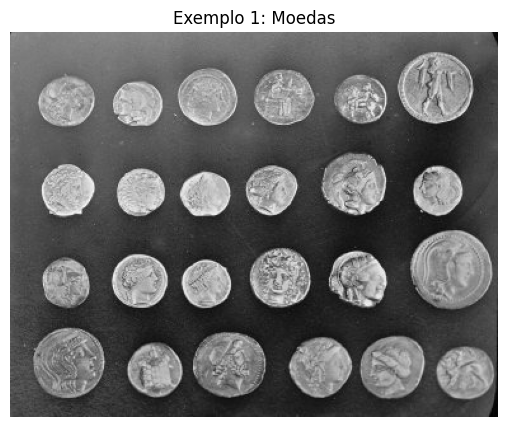

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import data, filters, segmentation, measure, morphology, color
import pandas as pd

# Aquisição da Imagem
img_moedas = data.coins()

plt.figure(figsize=(7, 5))
plt.imshow(img_moedas, cmap='gray')
plt.title('Exemplo 1: Moedas')
plt.axis('off')
plt.show()

## 1. Aquisição da imagem
Conforme sugerido, importou-se a imagem `coins` através do comando `data.coins()` da biblioteca `skimage`.

**Descrição do conteúdo:** A imagem ilustra diversas moedas de vários tamanhos dispostas sobre um fundo escuro. A iluminação não é perfeitamente uniforme (havendo um claro gradiente de luz no fundo) e o brilho dos reflexos metálicos no interior de algumas moedas dificulta a utilização de um limiar de segmentação global simples.

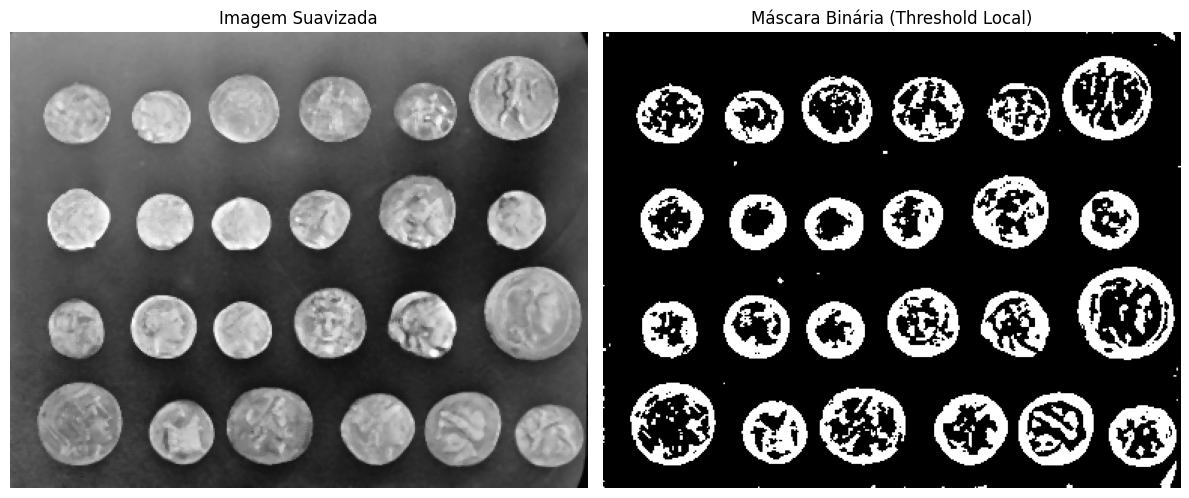

In [7]:
# 2. Segmentação da Imagem
# Suavização inicial com filtro de mediana para remover ruído isolado
img_suave = filters.median(img_moedas)

# Limiarização Adaptativa Local (Threshold Local)
block_size = 35 # Tamanho da vizinhança
offset = -10    # Ajuste fino para melhorar a captação das bordas

local_thresh = filters.threshold_local(img_suave, block_size, offset=offset)
binary = img_suave > local_thresh

# Criação da máscara
mask = binary

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_suave, cmap='gray'); axes[0].set_title('Imagem Suavizada'); axes[0].axis('off')
axes[1].imshow(mask, cmap='gray'); axes[1].set_title('Máscara Binária (Threshold Local)'); axes[1].axis('off')
plt.tight_layout()
plt.show()

## 2. Segmentação
**Método escolhido:** Optou-se pela **Limiarização Local (Threshold Local)** com um filtro de mediana prévio.
**Porquê?** Devido à iluminação irregular da imagem, limiares globais (como Otsu) falhariam em algumas áreas. O limiar local calcula um valor de corte específico para cada vizinhança, adaptando-se às variações de luz do fundo.

**Dificuldades observadas:** Embora a segmentação tenha capturado bem os contornos, os reflexos no interior das moedas criaram imensos "buracos" pretos dentro da máscara binária, que necessitam de correção na etapa seguinte.

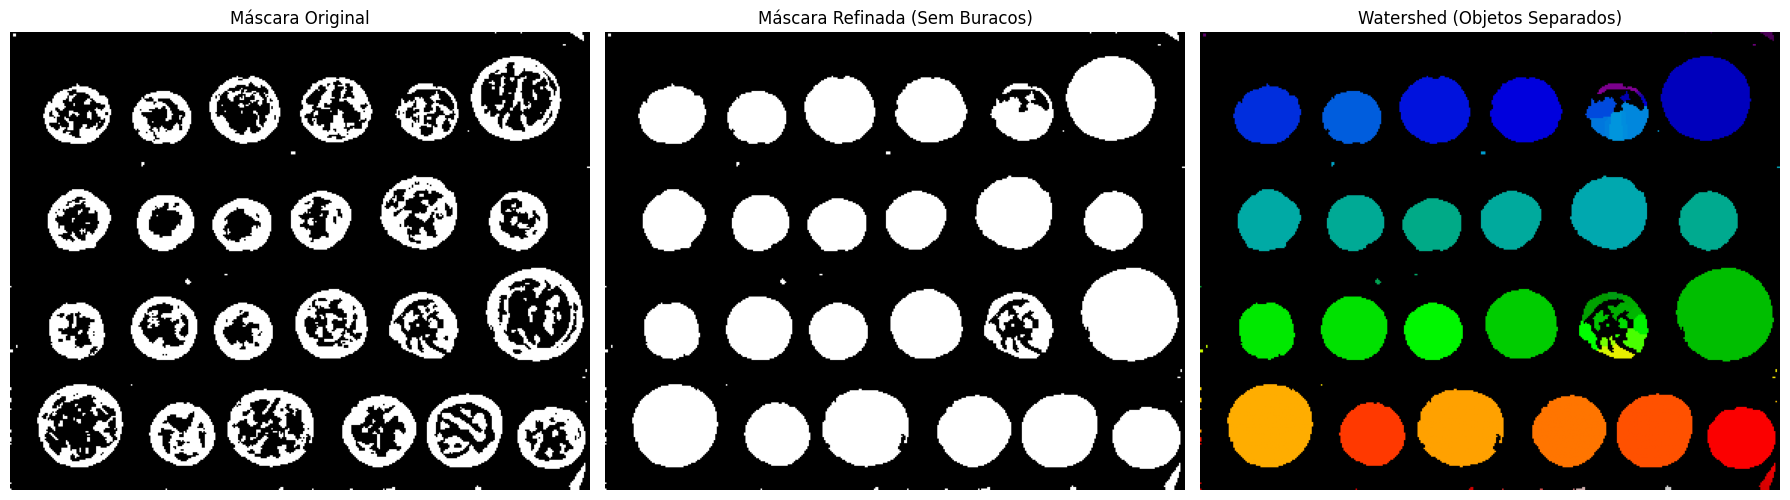

In [8]:
# 3. Operações Morfológicas e Watershed
#  Remover pequenos buracos internos nas moedas
mask_limpa = morphology.remove_small_holes(mask, area_threshold=1500)

#  Watershed para separar moedas coladas
#  Transformada de distância (calcula distância para o fundo)
dist = ndi.distance_transform_edt(mask_limpa)
neg_dist = -dist # Topografia invertida para o Watershed

#  Encontrar os vales (mínimos locais)
minimos = morphology.local_minima(neg_dist)
markers, num = ndi.label(minimos)

#  Aplicar Watershed
labels_ws = segmentation.watershed(neg_dist, markers, mask=mask_limpa)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(mask, cmap='gray'); axes[0].set_title('Máscara Original'); axes[0].axis('off')
axes[1].imshow(mask_limpa, cmap='gray'); axes[1].set_title('Máscara Refinada (Sem Buracos)'); axes[1].axis('off')
axes[2].imshow(labels_ws, cmap='nipy_spectral'); axes[2].set_title('Watershed (Objetos Separados)'); axes[2].axis('off')
plt.tight_layout()
plt.show()

## 3. Operações Morfológicas
Para refinar o resultado, aplicaram-se as seguintes técnicas:

1. **Remoção de Buracos (`remove_small_holes`):** O objetivo foi preencher os vazios gerados por reflexos nas moedas, tornando-as objetos sólidos. Na prática, funcionou muito bem para quase todas as moedas, mas falhou numa moeda específica (3ª linha, penúltima à direita), cujo reflexo/buraco era possivelmente maior que o limiar de área definido.
2. **Transformada de Distância e Watershed:** Calculou-se a distância de cada píxel de moeda até ao fundo. Os picos de distância serviram como sementes para o algoritmo de **Watershed**, cuja função vital foi criar uma fronteira de separação entre as moedas coladas. Contudo, devido ao buraco não fechado mencionado acima, o Watershed criou sementes a mais no interior dessa mesma moeda, fraturando-a em múltiplas regiões.

Quantidade de contornos após filtragem: 26


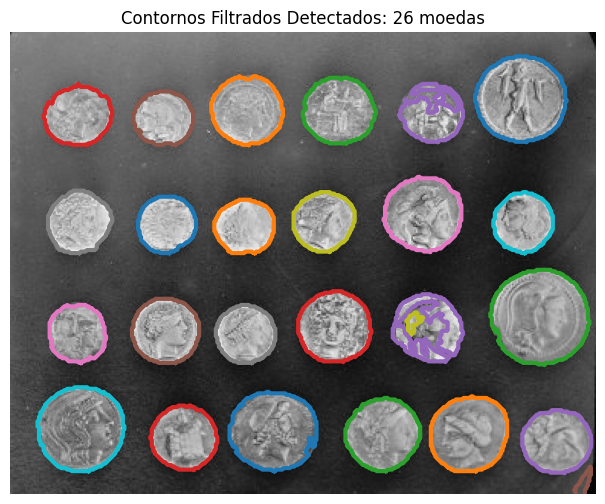

In [9]:
# 4. Detecção e Identificação de Objetos
# Extrair contornos da máscara limpa
contours = measure.find_contours(mask_limpa, level=0.5)

# Filtrar contornos irrelevantes (ruído)
contours_filtrados = [c for c in contours if len(c) > 50]
print(f"Quantidade de contornos após filtragem: {len(contours_filtrados)}")

plt.figure(figsize=(8, 6))
plt.imshow(img_moedas, cmap='gray')
for contour in contours_filtrados:
    plt.plot(contour[:, 1], contour[:, 0], linewidth=3)
plt.title(f'Contornos Filtrados Detectados: {len(contours_filtrados)} moedas')
plt.axis('off')
plt.show()

## 4. Identificação de Objetos
Utilizou-se a função `find_contours` do `skimage.measure` para delinear as bordas de cada objeto validado na máscara.

* **Número de objetos:** Foram identificados **26 objetos** distintos, após filtrar componentes residuais de ruído através da instrução `len(c) > 50`.
* **Análise (Sobre-segmentação):** Embora existam apenas 24 moedas na imagem, o algoritmo encontrou 26 contornos. Ao observar a imagem gerada, percebemos que a grande maioria das moedas foi identificada e separada perfeitamente. O erro ocorreu numa única moeda (3ª linha, 2ª a contar da direita) que, por ter mantido lacunas no seu interior durante as operações morfológicas, enganou o algoritmo de Watershed. O Watershed identificou múltiplos mínimos locais dentro dessa moeda, dividindo-a em 3 peças distintas, o que gerou contornos sobrepostos e elevou a contagem final de 24 para 26.

In [10]:
# 5. Extração de Características
propriedades = measure.regionprops(labels_ws)

dados = []
for i, prop in enumerate(propriedades):
    # Ignorar áreas mínimas que possam ter sobrado do Watershed
    if prop.area < 100:
        continue

    y0, x0 = prop.centroid

    dados.append({
        "Objeto ID": i + 1,
        "Área (px)": prop.area,
        "Perímetro (px)": round(prop.perimeter, 2),
        "Centroide (X)": round(x0, 1),
        "Centroide (Y)": round(y0, 1)
    })

df_caracteristicas = pd.DataFrame(dados)
display(df_caracteristicas)

,Objeto ID,Área (px),Perímetro (px),Centroide (X),Centroide (Y)
0,16,2590.0,188.75,334.7,43.5
1,19,1600.0,150.95,215.3,51.2
2,20,1626.0,150.61,155.2,51.0
3,21,1325.0,140.05,44.2,54.6
4,22,200.0,62.28,265.2,50.2
5,23,1084.0,125.81,100.3,56.2
6,26,268.0,73.53,287.6,57.4
7,28,152.0,50.86,275.1,62.5
8,33,1904.0,164.37,270.7,118.9
9,34,1296.0,133.88,44.7,124.3


## 5. Extração de Características
Recorrendo à função `regionprops` acoplada à matriz de rótulos gerada pelo Watershed, extraímos automaticamente três características cruciais exigidas: a **Área**, o **Perímetro** e o **Centroide** (coordenadas X e Y do centro de massa) de cada moeda identificada. Os dados foram estruturados na tabela acima.

## 6. Análise dos Resultados
* **Distinção de Objetos:** As características extraídas são altamente discriminativas e permitem separar claramente as moedas em diferentes grupos de tamanho. No entanto, os objetos resultantes da sobre-segmentação apresentarão áreas e perímetros anormais, não correspondentes a uma moeda real, distorcendo a tabela final.
* **Características Informativas:** A **Área** demonstra ser a característica mais constante e informativa para classificar o calibre físico da moeda, desde que a segmentação seja perfeita.
* **Melhorias no Pipeline:** Para corrigir o erro dos 26 contornos, o pipeline precisaria de um ajuste fino no pré-processamento. Aumentar o parâmetro `area_threshold` na função `remove_small_holes` (ou aplicar um Fechamento morfológico clássico mais agressivo) garantiria que a moeda problemática ficaria totalmente preenchida antes do Watershed.

## Conclusão
A implementação deste pipeline com a biblioteca `skimage` demonstrou que problemas complexos em Visão Computacional exigem soluções meticulosas. A limiarização local foi fundamental para ignorar o sombreamento do fundo. A prática evidenciou também que o sucesso de técnicas avançadas como o **Watershed** é totalmente dependente da qualidade da máscara binária que recebe: um pequeno buraco interior não tratado resultou numa sobre-segmentação detetável no final do processo. Esta atividade validou a importância da calibração de parâmetros morfológicos na extração fiável de características.